<a href="https://colab.research.google.com/github/robshan5/CS4287_project/blob/master/Nueral_computing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#https://www.kaggle.com/datasets/arnavr10880/concrete-crack-images-for-classification/data


# Try across yolo fast -cnn etc....
# yolo baseline - iteration 1
# data augmentation - iteration 2
# data augmentation + padding - iteration 3
!pip install triton sam3
import kagglehub
from pathlib import Path
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
import math
import random
import cv2
from google.colab.patches import cv2_imshow
from huggingface_hub import login
import torch
from PIL import Image
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor
import matplotlib.patches as patches

/usr/local/lib/python3.13/dist-packages/sam3/model/sam3_video_inference.py:798: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.bfloat16)
/usr/local/lib/python3.13/dist-packages/sam3/model/sam3_video_inference.py:906: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.autocast(device_type="cuda", dtype=torch.bfloat16)


In [ ]:
path = Path(kagglehub.dataset_download("arunrk7/surface-crack-detection",output_dir="/content/surface-crack-detection")) # loading in the kaggle dataset
print(path)

for p in path.iterdir():
    print(p, "-", "dir" if p.is_dir() else "file")

Using Colab cache for faster access to the 'surface-crack-detection' dataset.
/kaggle/input/surface-crack-detection
/kaggle/input/surface-crack-detection/Negative - dir
/kaggle/input/surface-crack-detection/Positive - dir


In [ ]:
os.listdir(path / 'Positive')

['08450.jpg',
 '19812.jpg',
 '05938.jpg',
 '06122.jpg',
 '08536.jpg',
 '04168.jpg',
 '12903_1.jpg',
 '11742_1.jpg',
 '02371.jpg',
 '04377.jpg',
 '14986_1.jpg',
 '09924.jpg',
 '16306_1.jpg',
 '00767.jpg',
 '10961_1.jpg',
 '14163_1.jpg',
 '07457.jpg',
 '17375_1.jpg',
 '14127_1.jpg',
 '10435_1.jpg',
 '02360.jpg',
 '05222.jpg',
 '03999.jpg',
 '16261_1.jpg',
 '00266.jpg',
 '18489_1.jpg',
 '11265_1.jpg',
 '02450.jpg',
 '12521_1.jpg',
 '14922_1.jpg',
 '01496.jpg',
 '01600.jpg',
 '05248.jpg',
 '10058_1.jpg',
 '17571_1.jpg',
 '03508.jpg',
 '00847.jpg',
 '06957.jpg',
 '15430_1.jpg',
 '18853_1.jpg',
 '00822.jpg',
 '00614.jpg',
 '11282_1.jpg',
 '02856.jpg',
 '19798.jpg',
 '02621.jpg',
 '01850.jpg',
 '17020_1.jpg',
 '13046_1.jpg',
 '15107_1.jpg',
 '07015.jpg',
 '00878.jpg',
 '17118_1.jpg',
 '14789_1.jpg',
 '13328_1.jpg',
 '08020.jpg',
 '19674.jpg',
 '14235_1.jpg',
 '16460_1.jpg',
 '05183.jpg',
 '11327_1.jpg',
 '18505_1.jpg',
 '09214.jpg',
 '18588_1.jpg',
 '08273.jpg',
 '10553_1.jpg',
 '16008_1.jpg'

In [ ]:
print(f'Positive length = {len(os.listdir(path / "Positive"))}')
print(f'Negative length = {len(os.listdir(path / "Negative"))}')

Positive length = 20000
Negative length = 20000


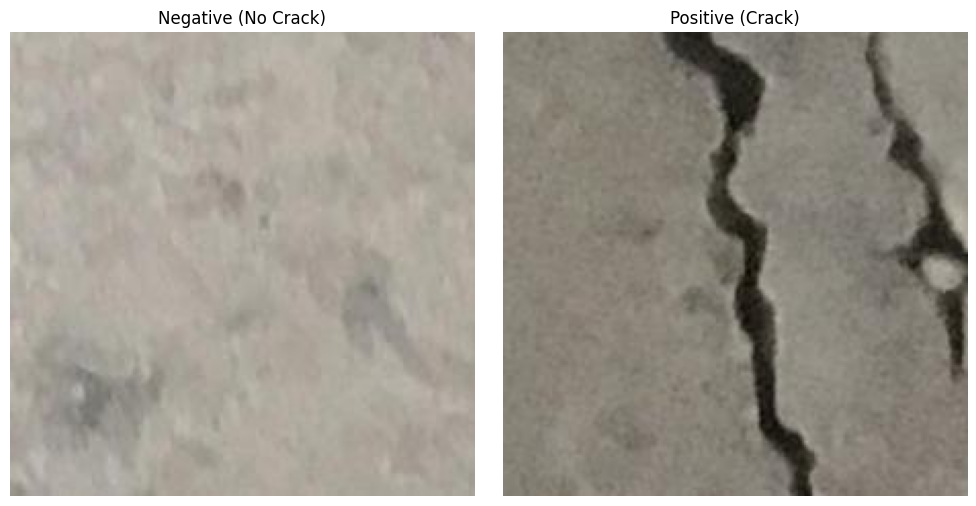

In [ ]:
random_positive = random.choice(os.listdir(path / 'Positive'))
random_negative = random.choice(os.listdir(path / 'Negative'))
img = mpimg.imread(os.path.join(path / 'Negative', random_negative))
img2 = mpimg.imread(os.path.join(path / 'Positive', random_positive))

fig, axes = plt.subplots(1, 2, figsize=(10, 5)) # 1 row, 2 column

axes[0].imshow(img)
axes[0].set_title('Negative (No Crack)')
axes[0].axis('off')

axes[1].imshow(img2)
axes[1].set_title('Positive (Crack)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Visualization of key attributes

In [ ]:
# shuffle dataset

# Trialing a grayscale filter


Sources
*   https://docs.opencv.org/3.1.0/dd/d49/tutorial_py_contour_features.html  - bounding rectangle
*   https://www.geeksforgeeks.org/python/image-thresholding-in-python-opencv/ - binary thresholding
* https://docs.opencv.org/3.4.20/da/d0c/tutorial_bounding_rects_circles.html - canny output
* https://github.com/jupyter/notebook/issues/3935 - cv2_imshow()
* https://docs.opencv.org/3.4.20/d7/d4d/tutorial_py_thresholding.html - cv2.Blur
* https://stackoverflow.com/questions/41586429/opencv-saving-images-to-a-particular-folder-of-choice - cv2.imwrite
* https://docs.opencv.org/4.13.0/dd/d49/tutorial_py_contour_features.html - cv2.contourArea
* https://stackoverflow.com/questions/701402/best-way-to-choose-a-random-file-from-a-directory - random



In [ ]:
dir_path = path / 'Positive'
os.makedirs("Output_dir_cv2", exist_ok=True)
for file in os.listdir(dir_path):
  img = cv2.imread(os.path.join(dir_path, file)) # read in our image
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # convert to gray
  src_gray = cv2.blur(gray, (3,3)) # filter out noise

  ret, thresh = cv2.threshold(src_gray, 100, 255, cv2.THRESH_BINARY) # establish a treshold of pixels
  edge = cv2.Canny(thresh,0, 100) # detect edges
  contours, hierarchy = cv2.findContours(edge,
                        cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE) # find contours

  area = -1
  index = -1
  for i,contour in enumerate(contours): # find the biggest contour
    temp_area = cv2.contourArea(contour)
    if temp_area > area:
      area = temp_area
      index = i

  if len(contours) > 0: # if we have a valid contour
    cnt = contours[index]
  else:
    continue

  x,y,w,h = cv2.boundingRect(cnt)

  cv2.rectangle(img,(x,y),(x+w,y+h),(255,255,255),2) # draw the bounding rectangle
  if area > 6.0:
    cv2.imwrite(f'Output_dir_cv2/{file}', img) # save to file
    print(f"{file} - {area}")
  else:
    print("rejecting")

Streaming output truncated to the last 5000 lines.
09914.jpg - 580.0
12725_1.jpg - 410.0
03238.jpg - 32.0
18857_1.jpg - 180.0
10215_1.jpg - 13.0
05991.jpg - 689.0
19236_1.jpg - 30.5
01694.jpg - 19.0
13979_1.jpg - 57.0
03949.jpg - 54.0
05333.jpg - 522.0
03682.jpg - 52.5
06340.jpg - 23.0
12642_1.jpg - 61.5
11790_1.jpg - 160.5
05883.jpg - 227.0
12715_1.jpg - 22.0
19112_1.jpg - 88.5
00631.jpg - 33.0
18601_1.jpg - 26.0
05387.jpg - 13.0
08949.jpg - 40.0
12247_1.jpg - 32.5
11124_1.jpg - 30.5
14531_1.jpg - 340.5
15498_1.jpg - 23.5
15069_1.jpg - 206.5
09861.jpg - 34.5
06901.jpg - 29.5
18790_1.jpg - 36.5
18284_1.jpg - 14.5
08935.jpg - 15.5
02979.jpg - 298.5
08159.jpg - 45.5
14769_1.jpg - 21.0
19450.jpg - 9.0
14866_1.jpg - 23.0
17625_1.jpg - 45.5
02054.jpg - 78.0
02056.jpg - 76.0
12796_1.jpg - 69.0
05668.jpg - 92.5
12958_1.jpg - 53.0
04065.jpg - 17.5
11140_1.jpg - 55.0
03596.jpg - 340.0
09672.jpg - 191.5
13498_1.jpg - 99.0
04216.jpg - 19.5
16784_1.jpg - 61.5
07306.jpg - 122.0
15590_1.jpg - 26.5
1

In [ ]:
print(len(os.listdir('/content/Output_dir_cv2')))

19786


In [ ]:
def random_images(n):

  random_files = []
  for i in range(n):
    random_file=random.choice(os.listdir("/content/Output_dir_cv2"))
    if random_file not in random_files and random_file.endswith(".jpg"):
      random_files.append(random_file)
  return random_files


['16614_1.jpg', '05300.jpg', '11212_1.jpg', '00777.jpg', '06792.jpg', '00142.jpg', '00241.jpg', '02319.jpg', '17784_1.jpg', '03671.jpg', '05733.jpg', '06076.jpg', '08349.jpg', '10512_1.jpg', '18562_1.jpg', '07830.jpg']


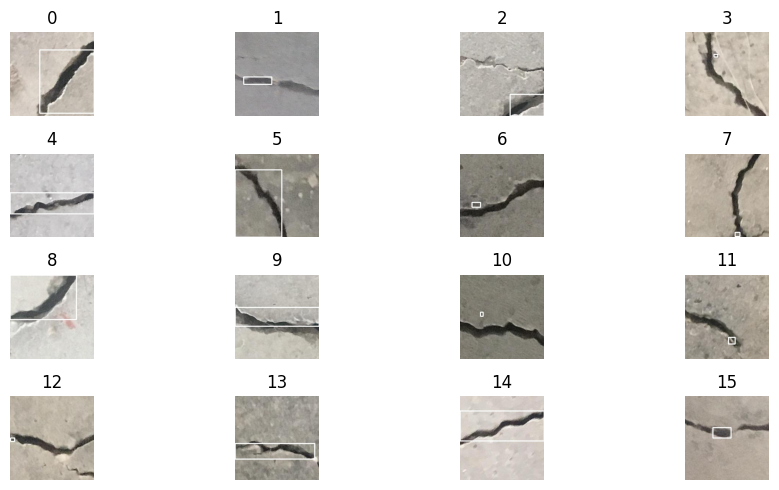

In [ ]:
random_files = random_images(16)
print(random_files)
path = '/content/Output_dir_cv2'
#img_list = [mpimg.imread(os.path.join(path, img)) for img in os.listdir(path) if img.endswith('.jpg')] # a list of all our jpg images

fig, axes = plt.subplots(math.ceil(len(random_files) / 4), 4, figsize=(10, 5)) # four images per row
axes = axes.flatten()
for i,_ in enumerate(random_files):
  axes[i].imshow(mpimg.imread(os.path.join(path, random_files[i])))
  axes[i].set_title(f'{i}')
  axes[i].axis('off')

for i in range(len(random_files), len(axes)): # turn off unused axes
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Using SAM

This is just me experimenting with using Meta's SAM model to automatically generate bounding boxes for our crack images. These bounded images can later be used in Yolo to detect our cracks

Many of the code exceprts shown below are being used from:

https://colab.research.google.com/github/roboflow-ai/notebooks/blob/main/notebooks/how-to-segment-anything-with-sam.ipynb?ref=blog.roboflow.com

When running this section ensure runtime is set to a GPU or else SAM takes ages

https://roboflow.com/blog/how-to-use-segment-anything-model-sam

Sam3 is really good. Sam1 is kinda mid



In [ ]:
"""
!pip install -q 'git+https://github.com/facebookresearch/segment-anything.git'
!pip install supervision
import supervision as sv
"""


In [ ]:
"""
HOME = os.getcwd()
print("HOME:", HOME)
CHECKPOINT_PATH = os.path.join(HOME, "weights", "sam_vit_h_4b8939.pth")
print(CHECKPOINT_PATH, "; exist:", os.path.isfile(CHECKPOINT_PATH))"""


In [ ]:
"""
!mkdir -p {HOME}/weights
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth -P {HOME}/weights"""


In [ ]:
"""
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
MODEL_TYPE = "vit_h"""""


In [ ]:
"""
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH).to(device=DEVICE)"""


In [ ]:
"""mask_generator = SamAutomaticMaskGenerator(sam)"""


In [ ]:
"""IMAGE_PATH = "/content/surface-crack-detection/Positive/00001.jpg"""


In [ ]:
"""image_bgr = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

sam_result = mask_generator.generate(image_rgb)"""


In [ ]:
"""print(sam_result[0].keys())"""


In [ ]:
"""mask_annotator = sv.MaskAnnotator(color_lookup=sv.ColorLookup.INDEX)

detections = sv.Detections.from_sam(sam_result=sam_result)

annotated_image = mask_annotator.annotate(scene=image_bgr.copy(), detections=detections)

sv.plot_images_grid(
    images=[image_bgr, annotated_image],
    grid_size=(1, 2),
    titles=['source image', 'segmented image']
)"""


## Issues with SAM1 approach


*   Random noise detected in image
*   Crack itself isnt been detected as a filter
*   Sam boundart detection isnt consistent

Maybe image processing could fix this issue if we made the crack darker and the surrounding regions brigther?



In [ ]:
"""masks = [
    mask['segmentation']
    for mask
    in sorted(sam_result, key=lambda x: x['area'], reverse=True)
]


sv.plot_images_grid(
    images=masks,
    grid_size=(8, math.ceil(len(masks) / 8)),
    titles=[str(i) for i in range(len(masks))]
)"""


## Experimenting with sam3

Many of the code excerpts shown below are from
https://github.com/facebookresearch/sam3

https://huggingface.co/facebook/sam3

I need to request access to SAM3 on hugging face so it might take a while

In [ ]:
## AI Usage report ----

"""
Prompt explain this error ....

/usr/local/lib/python3.13/dist-packages/iopath/common/file_io.py in _open(self, path, mode, buffering, encoding, errors, newline, closefd, opener, **kwargs)
    643
    644         self._check_kwargs(kwargs)
--> 645         return open(  # type: ignore
    646             self._get_path_with_cwd(path),
    647             mode,


FileNotFoundError: [Errno 2] No such file or directory: '/usr/local/lib/python3.13/dist-packages/assets/bpe_simple_vocab_16e6.txt.gz'

Output...

Advice regarding how to fix my python environment
"""
!mkdir -p /usr/local/lib/python3.13/dist-packages/assets

!wget -O /usr/local/lib/python3.13/dist-packages/assets/bpe_simple_vocab_16e6.txt.gz \
    https://github.com/openai/CLIP/raw/main/clip/bpe_simple_vocab_16e6.txt.gz
# AI usage report

--2026-10-06 14:29:54--  https://github.com/openai/CLIP/raw/main/clip/bpe_simple_vocab_16e6.txt.gz
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/openai/CLIP/main/clip/bpe_simple_vocab_16e6.txt.gz [following]
--2026-10-06 14:29:54--  https://raw.githubusercontent.com/openai/CLIP/main/clip/bpe_simple_vocab_16e6.txt.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1356917 (1.3M) [application/octet-stream]
Saving to: ‘/usr/local/lib/python3.13/dist-packages/assets/bpe_simple_vocab_16e6.txt.gz’

/usr/local/lib/pyth 100%[===================>]   1.29M  --.-KB/s    in 0.05s   

2026-10-06 14:29:54 (

In [ ]:
#Authentication with huggingface
login()

In [ ]:
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126


In [ ]:
# Load the model forcing CPU device
model = build_sam3_image_model(device="cpu")
processor = Sam3Processor(model, device="cpu")

AssertionError: Torch not compiled with CUDA enabled

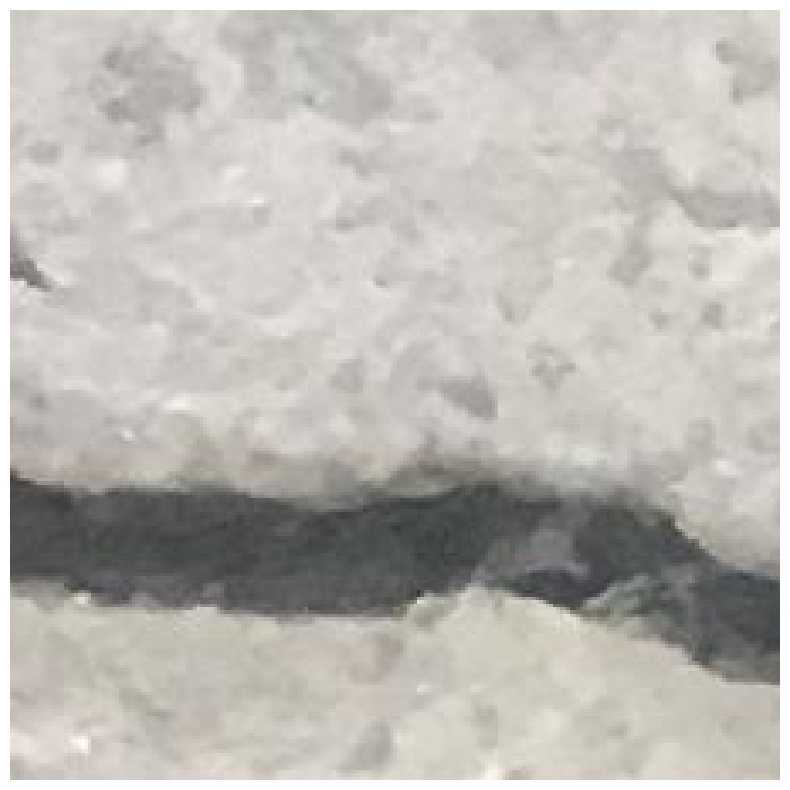

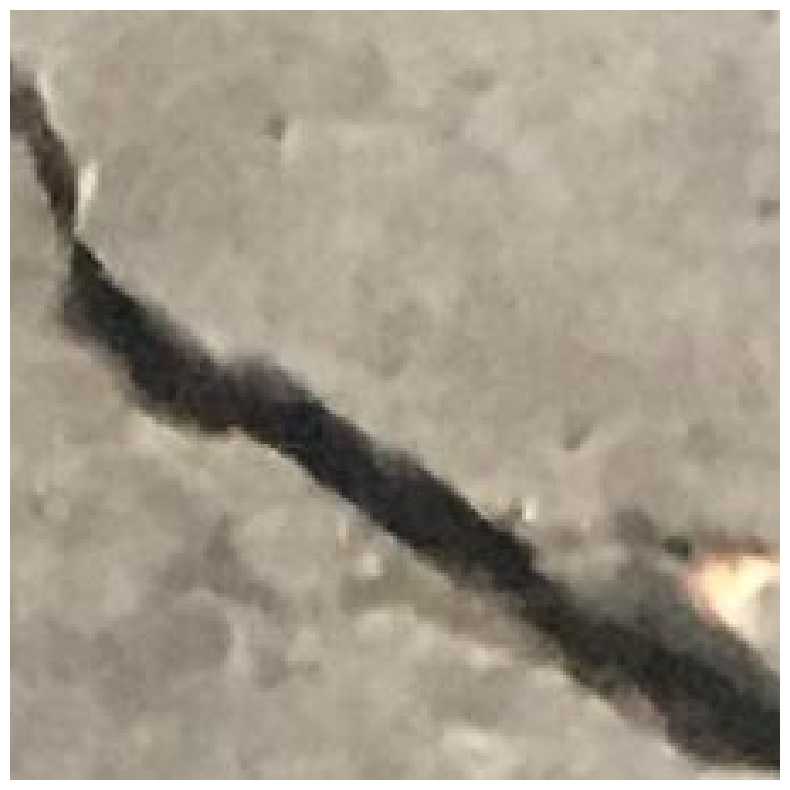

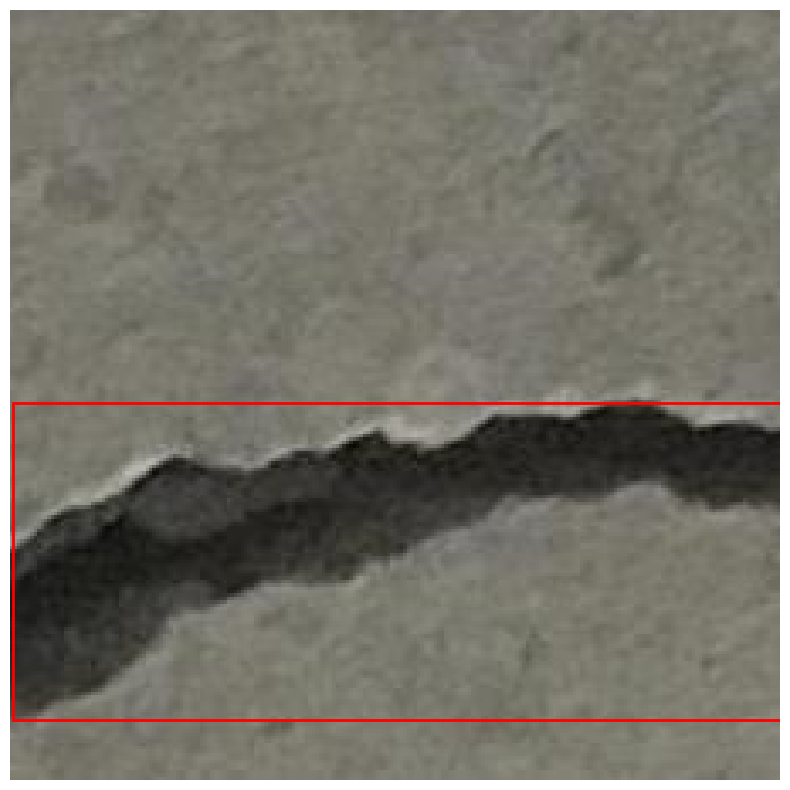

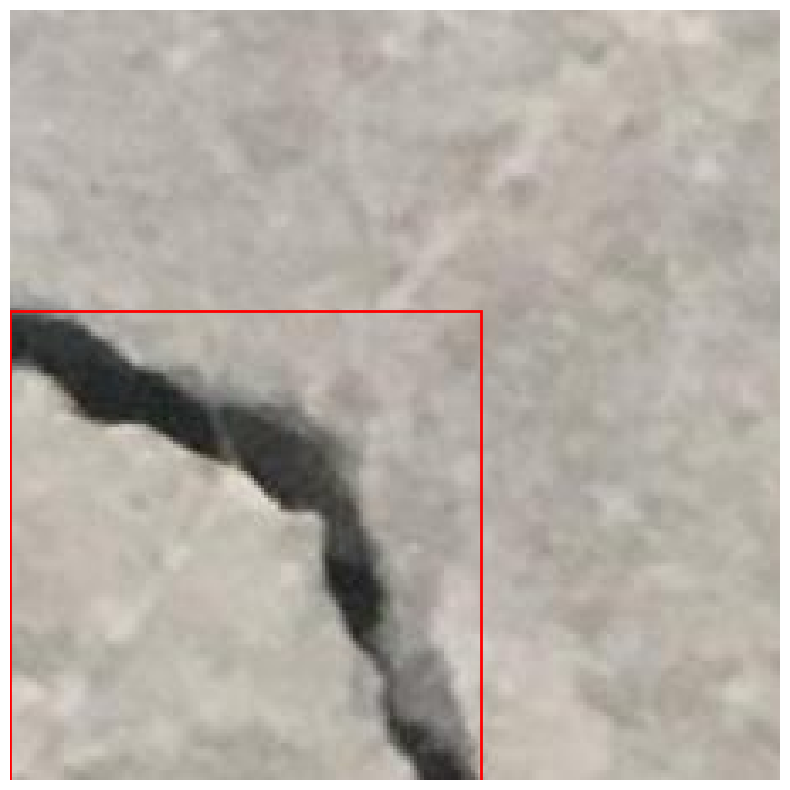

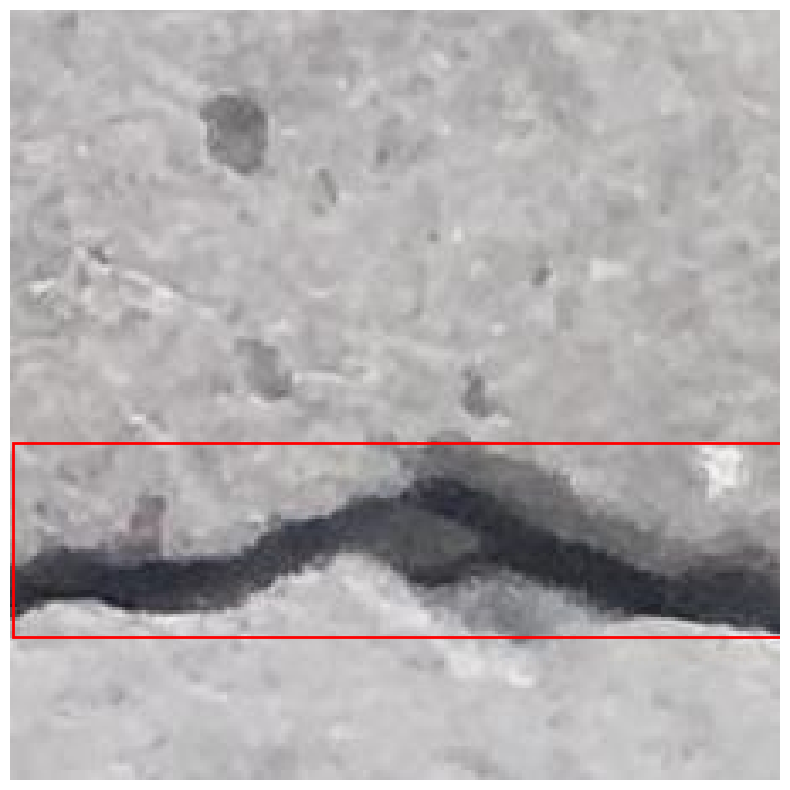

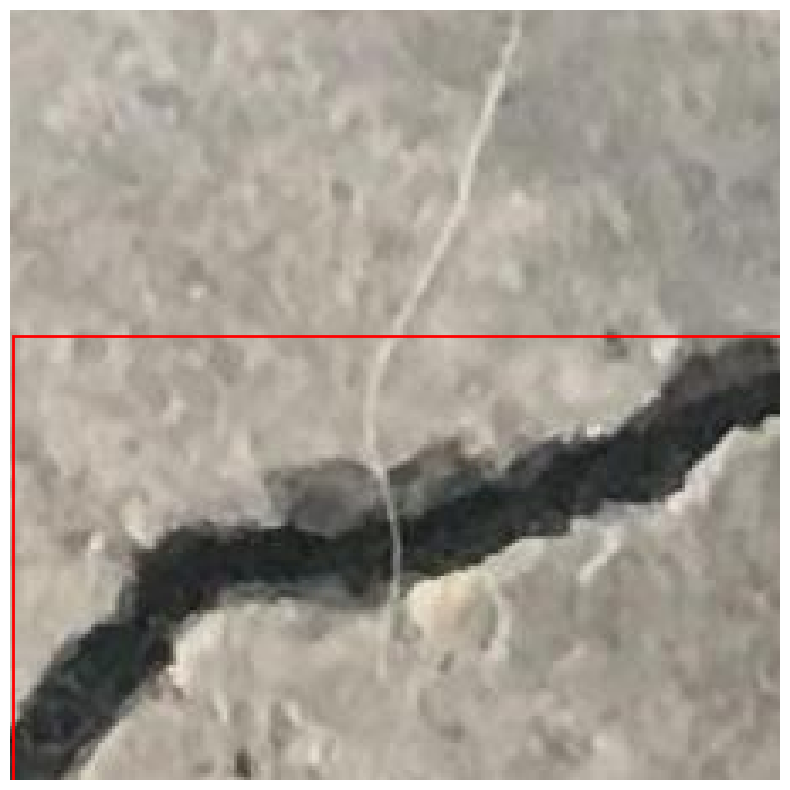

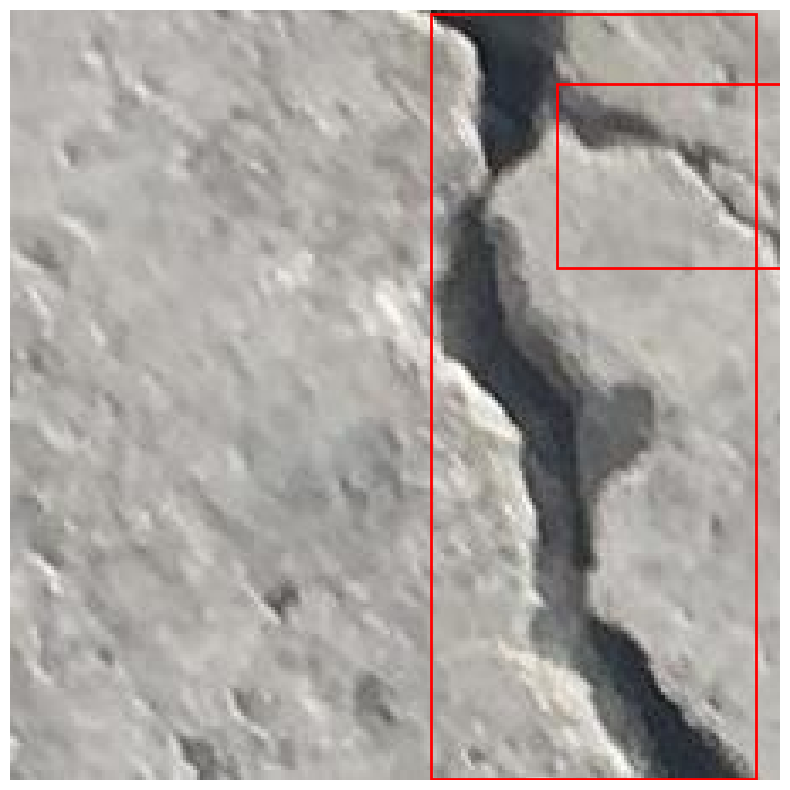

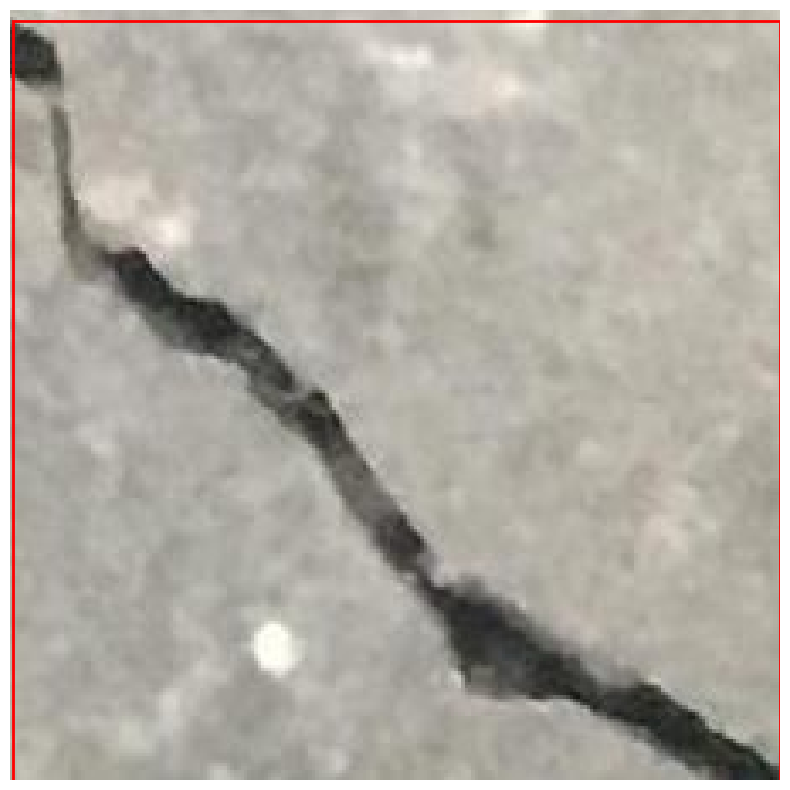

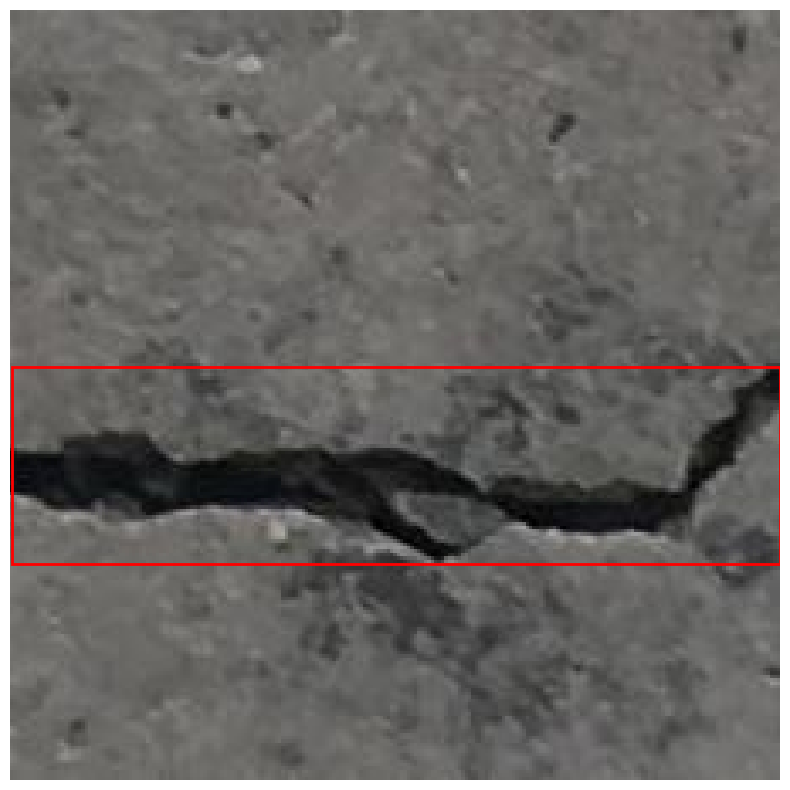

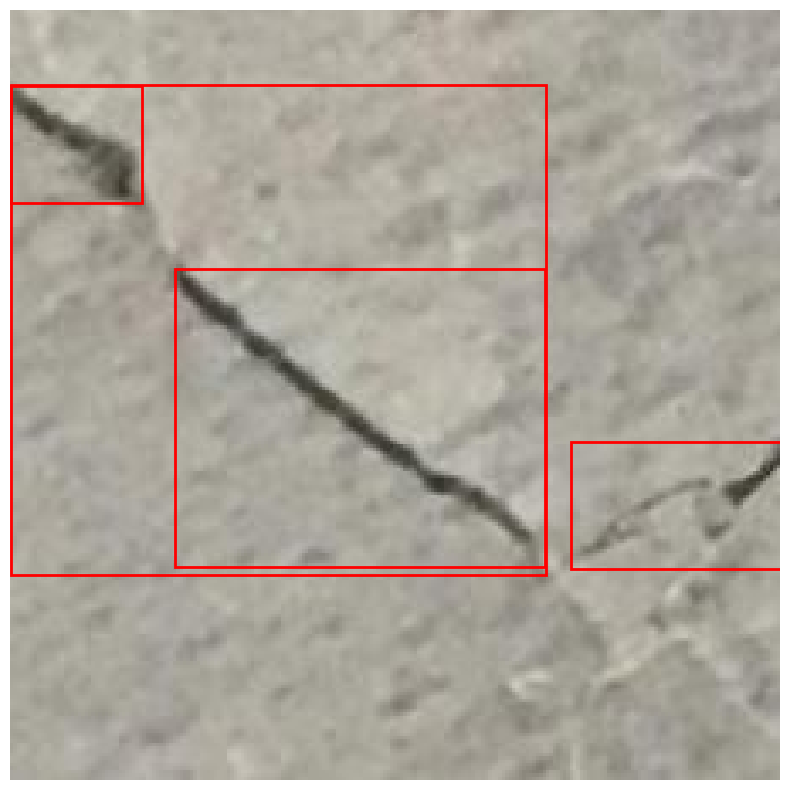

In [14]:
dir_path = '/content/surface-crack-detection/Positive'
os.makedirs("Output_dir_sam3", exist_ok=True)
mask_list = []
for file in os.listdir(dir_path)[:10]:
  # Load an image
  image = Image.open(os.path.join(dir_path,file))
  inference_state = processor.set_image(image)
  # Prompt the model with text
  output = processor.set_text_prompt(state=inference_state, prompt="Long, thin cracks on the surface of concrete")

  # Get the masks, bounding boxes, and scores
  masks, boxes, scores = output["masks"], output["boxes"], output["scores"]
  mask_list.append([image, masks])

  fig, ax = plt.subplots(figsize=(10, 10))
  ax.imshow(image)
  for box in boxes:
      x1, y1, x2, y2 = box.cpu().numpy()

      rect = patches.Rectangle(
          (x1, y1),
          x2 - x1,
          y2 - y1,
          linewidth=2,
          edgecolor="red",
          facecolor="none"
      )

      ax.add_patch(rect)

  ax.axis("off")
  plt.savefig(f'Output_dir_sam3/{file}')


In [ ]:
random_files = random_images(16)
print(random_files)
path = '/content/Output_dir_sam3'
#img_list = [mpimg.imread(os.path.join(path, img)) for img in os.listdir(path) if img.endswith('.jpg')]

fig, axes = plt.subplots(math.ceil(len(random_files) / 4), 4, figsize=(20, 20)) # four images per row
axes = axes.flatten()
for i,_ in enumerate(random_files):
  axes[i].imshow(mpimg.imread(os.path.join(path, random_files[i])))
  axes[i].set_title(f'{i}')
  axes[i].axis('off')

for i in range(len(random_files), len(axes)): # turn off unused axes
    axes[i].axis('off')
plt.tight_layout()
plt.show()

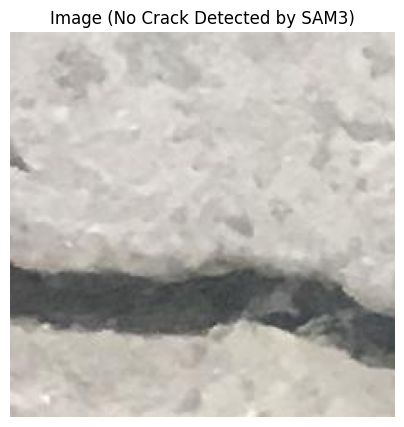

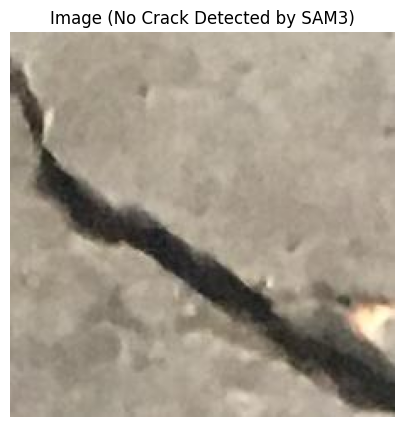

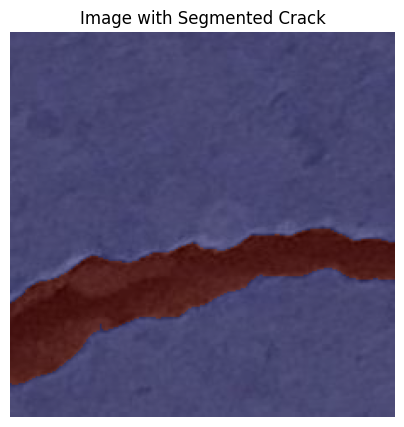

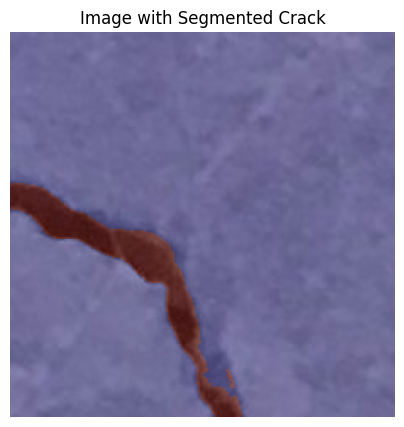

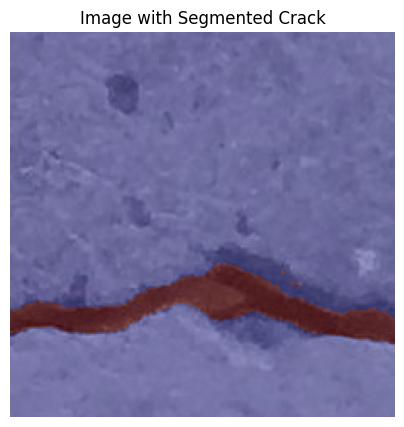

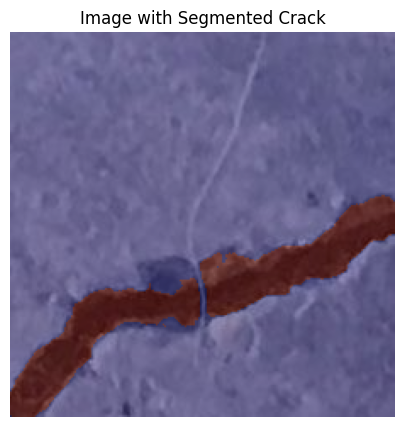

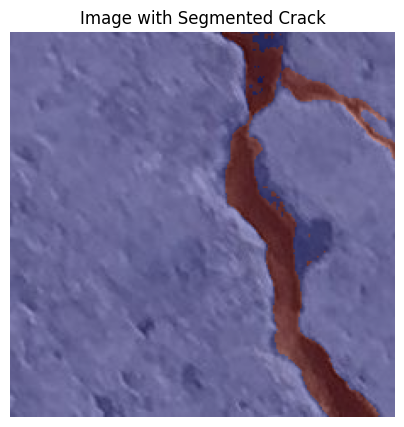

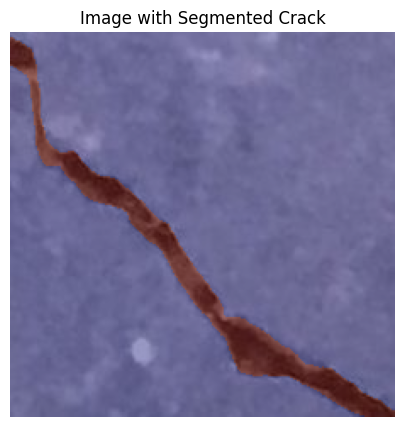

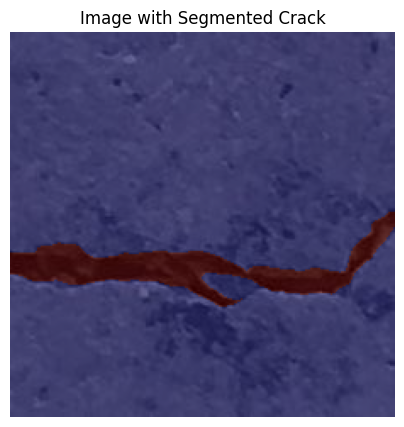

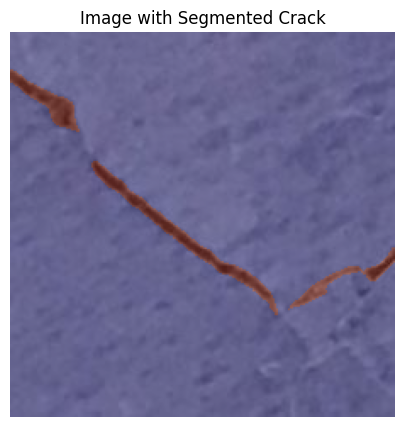

In [20]:
for image, mask in mask_list:
    plt.figure(figsize=(5, 5))
    plt.imshow(image)

    # Check if the mask tensor is not empty
    if mask is not None and mask.numel() > 0:
        # Convert to numpy and squeeze
        mask_np = mask.cpu().numpy().squeeze()

        # If there are multiple masks, plot them or take their union/maximum
        if mask_np.ndim == 3:
            # If we have multiple masks, we can overlay them by taking the maximum across masks
            mask_np = mask_np.any(axis=0)

        # Overlay the mask with transparency
        plt.imshow(mask_np, cmap='jet', alpha=0.4)
        plt.title("Image with Segmented Crack")
    else:
        plt.title("Image (No Crack Detected by SAM3)")

    plt.axis("off")
    plt.show()